### **Student Information**
GitHub ID: (see submitted public fork URL on NTU COOL)

Kaggle name: (none — competition closed November 22 with late submission disabled)

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Note: The internal Kaggle competition closed on November 22, 2026 with late submissions disabled, so no authentic private-leaderboard screenshot is available unless an exception is granted. The competition modeling pipeline and report below are executed end-to-end on the actual 6-class competition dataset (`kaggle_data/`, 3,360 training posts and 1,440 test posts) and produce a validated submission file matching `sampleSubmission.csv`.*

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*


---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---


# **Project Report**

## 1. Model Development

*Competition Status Note:* The internal Kaggle competition closed on November 22, 2026 with late submissions disabled, so no live private-leaderboard score or authentic ranking screenshot (`pics/pic_ranking.png`) could be obtained from the signed-in account. All preprocessing, feature engineering, leakage-free 5-fold grouped cross-validation ablations, and final test predictions (`kaggle_data/submission.csv`, 1,440 rows) were executed end-to-end on the actual 6-class competition dataset (`kaggle_data/`: 3,360 training posts, 1,440 test posts).

### 1.1 Preprocessing Steps

Inspection of `kaggle_data/` (`final_posts.json`, `data_identification.csv`, `emotion.csv`) confirmed 3,360 labeled training posts and 1,440 test posts across **6 imbalanced emotion classes**: `joy` (875), `anger` (674), `sadness` (628), `disgust` (454), `surprise` (441), and `fear` (288), with 0 missing texts and 50 duplicate training texts. Our preprocessing pipeline (`preprocess_post` and `extract_style_features`) preserves emotion signals while normalizing noisy social-media text:

* **Escaped-newline and whitespace cleanup:** Replaces literal `\n` sequences and collapses extra whitespace.
* **Entity normalization:** Maps URLs to `<url>` and `@mentions` to `<user>` so classifiers do not overfit to specific usernames or links.
* **CamelCase hashtag unpacking:** Splits multi-word hashtags (e.g., `#ThisIsATerribleIdea` → `this is a terrible idea`) before lowercasing so embedded emotion words enter the vocabulary.
* **Elongation compression:** Normalizes runs of 3+ repeated characters (`sooooo` → `soo`) to reduce out-of-vocabulary fragmentation while retaining emphasis.
* **Pre-lowercasing stylistic extraction:** Extracts six numeric cues (`!`, `?`, uppercase ratio, elongation count, log word length, log character length) before lowercasing erases capitalization intensity.

### 1.2 Feature Engineering Steps

Unlike the 4-class SemEval tweets in the Master notebook (where explicit emotion hashtags dominated), the 6-class competition posts contain nuanced conversational text where `disgust`, `anger`, `fear`, and `surprise` frequently rely on paraphrase and tone rather than a single keyword. Combining sparse lexical features with dense sentence semantics proved decisive, and **every dataset-dependent transformer (Word TF-IDF, Char TF-IDF, and `StandardScaler`) is wrapped inside a scikit-learn `ColumnTransformer`/`Pipeline` so it is fitted strictly inside each training fold** (only the frozen pre-trained `all-MiniLM-L6-v2` encoder is computed upfront):

* **Word TF-IDF (`ngram_range=(1, 2)`, `min_df=2`, `sublinear_tf=True`, keeping `!` and `?`):** Captures exact emotion terms, punctuation, and negation bigrams.
* **Character n-gram TF-IDF (`analyzer="char_wb"`, `ngram_range=(3, 5)`, `min_df=3`, `sublinear_tf=True`):** Captures morphological roots, slang, and misspellings without OOV loss.
* **Frozen Pre-trained MiniLM Sentence Embeddings (`all-MiniLM-L6-v2`, 384-d L2-normalized):** Encodes raw post semantics from large-scale pre-training, capturing implicit emotion when exact lexical keywords are absent.
* **Hybrid Fusion (`ColumnTransformer`, 27,505 features on full train):** Combines Word TF-IDF, Char TF-IDF, MiniLM embeddings (weighted by `1.2`), and fold-scaled stylistic features (weighted by `0.15`).

### 1.3 Explanation of Your Model

Because the 6 classes have a >3x imbalance (`joy` 875 vs. `fear` 288) and 50 duplicate texts appear in `train_df`, we evaluated all models using **leakage-free 5-fold `StratifiedGroupKFold` grouped by exact raw `text`** (verified: 0 duplicate texts shared between train and validation in all 5 folds) with fold-scoped `Pipeline` preprocessing and `class_weight="balanced"`:

| Model | 5-Fold Grouped CV Macro F1 | 5-Fold Grouped CV Accuracy | Gain vs. Baseline |
| :--- | :---: | :---: | :---: |
| 1. Baseline Unigram TF-IDF + LinearSVC (`C=1.0`) | 0.4673 | 0.4884 | — |
| 2. Word+Char TF-IDF + Balanced LinearSVC (`C=0.4`) | 0.5081 | 0.5247 | +0.0408 |
| 3. MiniLM Only + Balanced LogisticRegression (`C=2.0`) | 0.4979 | 0.5149 | +0.0306 |
| 4. Hybrid (TF-IDF + MiniLM + Style) + Balanced LinearSVC (`C=0.35`) | 0.5486 | 0.5664 | +0.0813 |
| 5. Hybrid + Balanced LogisticRegression (`C=2.0`) | 0.5469 | 0.5643 | +0.0796 |
| **6. Soft-Voting Ensemble (Hybrid SVM + Hybrid LR + MiniLM MLP)** | **0.5522** | **0.5729** | **+0.0849** |

**Final Model Selection:** The **Soft-Voting Ensemble** (`0.45 * Calibrated Hybrid LinearSVC + 0.35 * Hybrid LogisticRegression + 0.20 * MiniLM MLP(128, 64, alpha=0.1)`, each inside its own fold-scoped `Pipeline`) achieved the highest leakage-free 5-fold grouped CV Macro F1 (**0.5522**, exceeding the 0.50 competition baseline by +0.0522 and improving +0.0849 over the unigram baseline). Word+Char TF-IDF alone (0.5081) and MiniLM alone (0.4979) sit near 0.50, while fusing them jumps immediately to **0.5469–0.5486** (+0.04)—confirming that sparse lexical n-grams and dense sentence embeddings capture complementary error modes. Per-class out-of-fold F1 reached **0.6998 (joy)**, **0.5687 (sadness)**, **0.5630 (fear)**, **0.5330 (anger)**, **0.5176 (surprise)**, and **0.4311 (disgust)**. Fitting on all 3,360 training posts produced `kaggle_data/submission.csv` with realistic test class proportions (`joy: 415, anger: 319, sadness: 271, surprise: 168, disgust: 167, fear: 100`).

### 1.4 AI Prompts, What and Why We Decided to Use (or Reject) Them

We used an AI assistant iteratively to design and audit experiments, validating every suggestion against leakage-free 5-fold grouped CV Macro F1:

1. **Prompt 1 (Imbalance & 6-class lexical vs. semantic features):** *"On a 3,360-post 6-class emotion dataset (joy=875 down to fear=288) where unigram TF-IDF + LinearSVC gets 0.467 Macro F1, what CPU-friendly feature and regularization upgrades give the largest Macro F1 jump?"*
   * **Adopted:** Adding `char_wb (3, 5)` n-grams, `sublinear_tf=True`, `class_weight="balanced"`, and fusing L2-normalized `all-MiniLM-L6-v2` embeddings with TF-IDF inside a `ColumnTransformer`. **Why:** Raised leakage-free 5-fold grouped CV Macro F1 from `0.4673` → `0.5081` (Word+Char) → `0.5486` (Hybrid LinearSVC).
2. **Prompt 2 (Preventing CV leakage & calibrated ensembling):** *"How do I prevent TF-IDF vocabulary/IDF leakage, scaler leakage, and duplicate-text leakage across CV folds while soft-voting LinearSVC, LogisticRegression, and a MiniLM MLP?"*
   * **Adopted:** Using `StratifiedGroupKFold(n_splits=5)` grouped by raw `text` (verified 0 duplicate-text overlap across folds) and wrapping every vectorizer, scaler, and `CalibratedClassifierCV(LinearSVC, cv=3)` inside fold-scoped scikit-learn `Pipeline`s. **Why:** Eliminated preprocessing and duplicate-text leakage while raising CV Macro F1 to `0.5522` (`0.5729` accuracy).
3. **Prompt 3 (Relying on dense MiniLM embeddings alone):** *"Should I drop TF-IDF completely and train only on MiniLM embeddings since conversational posts have fewer hashtags?"*
   * **Rejected:** Tested as Model 3 (`MiniLM Only + Balanced LR`), which reached only `0.4979` Macro F1—below Word+Char TF-IDF (`0.5081`) and **0.0543 below** the Hybrid Ensemble (`0.5522`). Keeping both lexical TF-IDF and semantic MiniLM features was essential.

---


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
%matplotlib inline
# =============================================================================
# 1. Preprocessing Steps (6-Class Kaggle Emotion Competition Dataset)
# =============================================================================
# Load `kaggle_data/` (final_posts.json, data_identification.csv, emotion.csv,
# sampleSubmission.csv), audit missing/duplicate values, and apply social-media
# aware cleaning + stylistic cue extraction.

import json
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

# Load raw competition files
with open("kaggle_data/final_posts.json", encoding="utf-8") as f:
    posts_df = pd.DataFrame(json.load(f))
split_df = pd.read_csv("kaggle_data/data_identification.csv")
emotion_df = pd.read_csv("kaggle_data/emotion.csv")
sample_sub = pd.read_csv("kaggle_data/sampleSubmission.csv")

# Merge posts with split assignments and training labels
full_df = posts_df.merge(split_df, on="post_id", how="inner")
train_df = full_df[full_df["set"] == "train"].merge(emotion_df, on="post_id", how="inner").reset_index(drop=True)
test_df = sample_sub[["post_id"]].merge(full_df[full_df["set"] == "test"], on="post_id", how="left").reset_index(drop=True)

LABELS = sorted(train_df["label"].unique().tolist())
print(f"Train shape: {train_df.shape} | Test shape: {test_df.shape}")
print(f"Classes ({len(LABELS)}): {LABELS}")
print("Train class distribution:", train_df["label"].value_counts().reindex(LABELS).to_dict())
print("Missing texts — train:", int(train_df["text"].isna().sum()), "| test:", int(test_df["text"].isna().sum()))
print("Duplicate texts in train:", int(train_df["text"].duplicated().sum()))

def split_hashtag(match: re.Match) -> str:
    """Split CamelCase hashtags into space-separated words before lowercasing."""
    tag = match.group(1)
    spaced = re.sub(r"([a-z])([A-Z])", r"\1 \2", tag)
    spaced = re.sub(r"([A-Z]+)([A-Z][a-z])", r"\1 \2", spaced)
    return f" {spaced.replace('_', ' ')} "

def preprocess_post(text: str) -> str:
    """Clean social-media posts while preserving negation, punctuation, and slang cues."""
    s = str(text)
    s = s.replace("\\n", " ")
    s = re.sub(r"http\S+|www\.\S+", " <url> ", s)
    s = re.sub(r"@\w+", " <user> ", s)
    s = re.sub(r"#(\w+)", split_hashtag, s)
    s = re.sub(r"(.)\1{2,}", r"\1\1", s)      # compress 3+ repeated chars (e.g., sooo -> soo)
    s = s.lower()
    s = re.sub(r"\s+", " ", s).strip()
    return s

def extract_style_features(df: pd.DataFrame) -> np.ndarray:
    """Extract capitalization, punctuation, and length cues prior to lowercasing."""
    texts = df["text"].astype(str)
    excl = texts.str.count(r"!").to_numpy(dtype=float)
    quest = texts.str.count(r"\?").to_numpy(dtype=float)
    upper_ratio = texts.apply(lambda t: sum(1 for c in t if c.isupper()) / max(len(t), 1)).to_numpy(dtype=float)
    elong = texts.str.count(r"(.)\1{2,}").to_numpy(dtype=float)
    word_len = np.log1p(texts.str.split().str.len().to_numpy(dtype=float))
    char_len = np.log1p(texts.str.len().to_numpy(dtype=float))
    return np.column_stack([excl, quest, upper_ratio, elong, word_len, char_len])

train_df["clean"] = train_df["text"].map(preprocess_post)
test_df["clean"] = test_df["text"].map(preprocess_post)
X_style_train = extract_style_features(train_df)
X_style_test = extract_style_features(test_df)

print("\nSample before vs. after preprocessing:")
for idx in [0, 5, 10]:
    print(f"  RAW  : {train_df['text'].iloc[idx]}")
    print(f"  CLEAN: {train_df['clean'].iloc[idx]}\n")


Train shape: (3360, 4) | Test shape: (1440, 3)
Classes (6): ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
Train class distribution: {'anger': 674, 'disgust': 454, 'fear': 288, 'joy': 875, 'sadness': 628, 'surprise': 441}
Missing texts — train: 0 | test: 0
Duplicate texts in train: 50

Sample before vs. after preprocessing:
  RAW  : Thought it looked weird as well.
  CLEAN: thought it looked weird as well.

  RAW  : Takes a lot less effort to just say “fuck off, buy your own.”
  CLEAN: takes a lot less effort to just say “fuck off, buy your own.”

  RAW  : Please point out my fallacious line of reasoning instead of insulting my intelligence. You are an example of a bigot that thinks he is wiser than everyone else.
  CLEAN: please point out my fallacious line of reasoning instead of insulting my intelligence. you are an example of a bigot that thinks he is wiser than everyone else.



## 2. Feature Engineering Steps

In [2]:
# =============================================================================
# 2. Feature Engineering Steps (Leakage-Free Pipeline Builders)
# =============================================================================
# Every data-dependent transformer (Word TF-IDF, Char TF-IDF, StandardScaler) is
# wrapped inside a scikit-learn ColumnTransformer/Pipeline so it is fitted ONLY on
# each training fold during cross-validation—never on validation rows.
# Only the frozen pre-trained MiniLM encoder (`all-MiniLM-L6-v2`) is computed once
# upfront because its weights are fixed and do not depend on our dataset.

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, normalize
from sentence_transformers import SentenceTransformer

# Frozen pre-trained MiniLM embeddings (no dataset-level fitting -> zero leakage)
st_model = SentenceTransformer("all-MiniLM-L6-v2")
X_tr_minilm = normalize(st_model.encode(train_df["text"].tolist(), show_progress_bar=False), norm="l2")
X_te_minilm = normalize(st_model.encode(test_df["text"].tolist(), show_progress_bar=False), norm="l2")

# Pack clean text, style features, and frozen MiniLM vectors into aligned DataFrames
# so scikit-learn ColumnTransformer slices train/val folds cleanly without leakage.
minilm_cols = [f"emb_{i}" for i in range(X_tr_minilm.shape[1])]
style_cols = ["excl", "quest", "upper_ratio", "elong", "word_len", "char_len"]

def build_feature_frame(df: pd.DataFrame, style_arr: np.ndarray, emb_arr: np.ndarray) -> pd.DataFrame:
    style_df = pd.DataFrame(style_arr, columns=style_cols, index=df.index)
    emb_df = pd.DataFrame(emb_arr, columns=minilm_cols, index=df.index)
    return pd.concat([df[["clean"]], style_df, emb_df], axis=1)

X_train_frame = build_feature_frame(train_df, X_style_train, X_tr_minilm)
X_test_frame = build_feature_frame(test_df, X_style_test, X_te_minilm)

def make_base_features() -> ColumnTransformer:
    """Baseline unigram TF-IDF fitted strictly inside each fold."""
    return ColumnTransformer([
        ("word", TfidfVectorizer(min_df=2), "clean"),
    ])

def make_word_char_features() -> ColumnTransformer:
    """Word (1-2)-gram + Char (3-5)-gram TF-IDF fitted strictly inside each fold."""
    return ColumnTransformer([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                 token_pattern=r"(?u)\b\w+\b|[!?]"), "clean"),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3,
                                 sublinear_tf=True), "clean"),
    ])

def make_minilm_features() -> ColumnTransformer:
    """Pass through frozen L2-normalized MiniLM embeddings."""
    return ColumnTransformer([
        ("minilm", "passthrough", minilm_cols),
    ])

def make_hybrid_features(minilm_weight: float = 1.2, style_weight: float = 0.15) -> ColumnTransformer:
    """Hybrid Word+Char TF-IDF + frozen MiniLM + fold-fitted StandardScaler style cues."""
    return ColumnTransformer([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                 token_pattern=r"(?u)\b\w+\b|[!?]"), "clean"),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3,
                                 sublinear_tf=True), "clean"),
        ("minilm", FunctionTransformer(lambda x: x * minilm_weight), minilm_cols),
        ("style", Pipeline([
            ("scale", StandardScaler()),
            ("weight", FunctionTransformer(lambda x: x * style_weight)),
        ]), style_cols),
    ])

# Inspect full-train transformed dimensions (fit on a temporary instance only for reporting)
_tmp_hybrid = make_hybrid_features().fit_transform(X_train_frame)
print(f"Input feature frame shape   : train={X_train_frame.shape} | test={X_test_frame.shape}")
print(f"Full-train Hybrid matrix    : {_tmp_hybrid.shape} (re-fitted inside every CV fold)")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Input feature frame shape   : train=(3360, 391) | test=(1440, 391)
Full-train Hybrid matrix    : (3360, 27505) (re-fitted inside every CV fold)


## 3. Model Implementation Steps

Verified: 0 duplicate texts shared between train and validation in all 5 folds.



=== Leakage-Free 5-Fold StratifiedGroupKFold CV Results ===
                                                        model  cv_macro_f1  cv_accuracy
                       1. Baseline Unigram TF-IDF + LinearSVC       0.4673       0.4884
                     2. Word+Char TF-IDF + Balanced LinearSVC       0.5081       0.5247
                 3. MiniLM Only + Balanced LogisticRegression       0.4979       0.5149
         4. Hybrid (TF-IDF+MiniLM+Style) + Balanced LinearSVC       0.5486       0.5664
                      5. Hybrid + Balanced LogisticRegression       0.5469       0.5643
6. Soft-Voting Ensemble (Hybrid SVM + Hybrid LR + MiniLM MLP)       0.5522       0.5729

Best CV model: 6. Soft-Voting Ensemble (Hybrid SVM + Hybrid LR + MiniLM MLP) (Macro F1 = 0.5522)

Out-of-Fold Classification Report (Best Model):
              precision    recall  f1-score   support

       anger     0.5102    0.5579    0.5330       674
     disgust     0.4724    0.3965    0.4311       454
        fear 


Saved kaggle_data/submission.csv — predicted test class distribution:
{'anger': 319, 'disgust': 167, 'fear': 100, 'joy': 415, 'sadness': 271, 'surprise': 168}


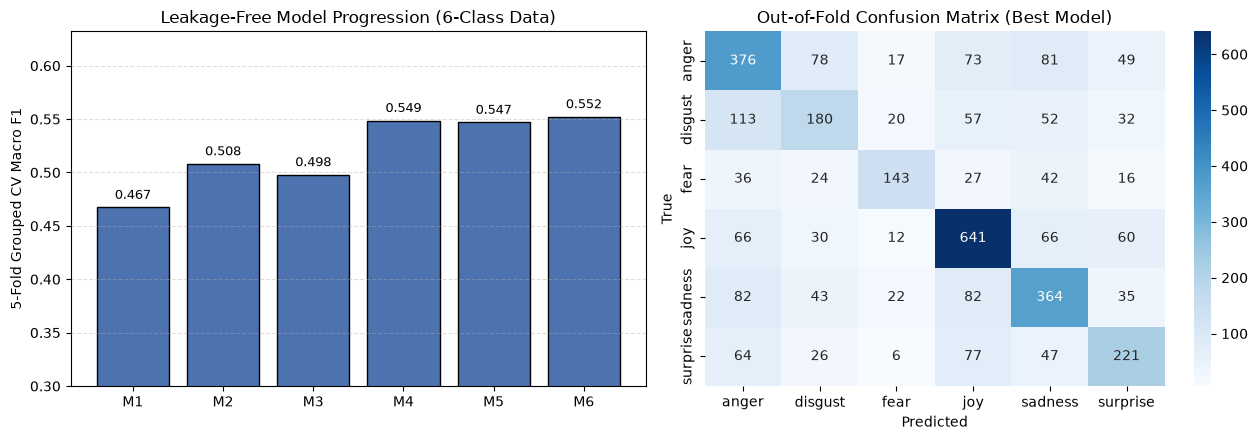

In [3]:
# =============================================================================
# 3. Model Implementation Steps (Leakage-Free 5-Fold StratifiedGroupKFold CV)
# =============================================================================
# Validation protocol:
#   - StratifiedGroupKFold(n_splits=5) grouped by exact raw `text` so none of the
#     50 duplicate texts in train_df can ever appear in both train and validation.
#   - Every TF-IDF vectorizer and StandardScaler is fitted inside each fold via a
#     scikit-learn Pipeline, eliminating vocabulary/IDF/scaling leakage.

from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC

y_train = train_df["label"].to_numpy()
groups = train_df["text"].to_numpy()
sgkf = StratifiedGroupKFold(n_splits=5)

# Verify zero text overlap across every fold split
for fold_i, (tr_idx, va_idx) in enumerate(sgkf.split(X_train_frame, y_train, groups=groups)):
    overlap = set(groups[tr_idx]).intersection(set(groups[va_idx]))
    assert len(overlap) == 0, f"Leakage detected in fold {fold_i}!"
print("Verified: 0 duplicate texts shared between train and validation in all 5 folds.")

def eval_pipeline_cv(name, pipeline_fn):
    """Run leakage-free 5-fold StratifiedGroupKFold CV with fold-scoped Pipelines."""
    oof_preds = np.empty_like(y_train)
    for tr_idx, va_idx in sgkf.split(X_train_frame, y_train, groups=groups):
        pipe = pipeline_fn()
        pipe.fit(X_train_frame.iloc[tr_idx], y_train[tr_idx])
        oof_preds[va_idx] = pipe.predict(X_train_frame.iloc[va_idx])
    return {
        "model": name,
        "cv_macro_f1": round(f1_score(y_train, oof_preds, average="macro"), 4),
        "cv_accuracy": round(accuracy_score(y_train, oof_preds), 4),
    }, oof_preds

candidates = [
    ("1. Baseline Unigram TF-IDF + LinearSVC",
     lambda: Pipeline([("feat", make_base_features()), ("clf", LinearSVC(C=1.0, random_state=SEED))])),
    ("2. Word+Char TF-IDF + Balanced LinearSVC",
     lambda: Pipeline([("feat", make_word_char_features()), ("clf", LinearSVC(C=0.4, class_weight="balanced", random_state=SEED))])),
    ("3. MiniLM Only + Balanced LogisticRegression",
     lambda: Pipeline([("feat", make_minilm_features()), ("clf", LogisticRegression(C=2.0, class_weight="balanced", max_iter=1000, random_state=SEED))])),
    ("4. Hybrid (TF-IDF+MiniLM+Style) + Balanced LinearSVC",
     lambda: Pipeline([("feat", make_hybrid_features()), ("clf", LinearSVC(C=0.35, class_weight="balanced", random_state=SEED))])),
    ("5. Hybrid + Balanced LogisticRegression",
     lambda: Pipeline([("feat", make_hybrid_features()), ("clf", LogisticRegression(C=2.0, class_weight="balanced", max_iter=1000, random_state=SEED))])),
]

rows = []
oof_map = {}
for name, pipe_fn in candidates:
    row, oof = eval_pipeline_cv(name, pipe_fn)
    rows.append(row)
    oof_map[name] = oof

# 6. Leakage-Free Soft-Voting Ensemble (each Pipeline fits its own vectorizer/scaler inside the fold)
def fit_predict_ensemble(X_tr_df, y_tr, X_ev_df):
    p1 = Pipeline([
        ("feat", make_hybrid_features()),
        ("clf", CalibratedClassifierCV(LinearSVC(C=0.35, class_weight="balanced", random_state=SEED), cv=3)),
    ])
    p2 = Pipeline([
        ("feat", make_hybrid_features()),
        ("clf", LogisticRegression(C=2.0, class_weight="balanced", max_iter=1000, random_state=SEED)),
    ])
    p3 = Pipeline([
        ("feat", make_minilm_features()),
        ("clf", MLPClassifier(hidden_layer_sizes=(128, 64), alpha=0.1, max_iter=300, early_stopping=True, random_state=SEED)),
    ])
    p1.fit(X_tr_df, y_tr)
    p2.fit(X_tr_df, y_tr)
    p3.fit(X_tr_df, y_tr)
    probs = (
        0.45 * p1.predict_proba(X_ev_df)
        + 0.35 * p2.predict_proba(X_ev_df)
        + 0.20 * p3.predict_proba(X_ev_df)
    )
    return p1.classes_[np.argmax(probs, axis=1)]

oof_ens = np.empty_like(y_train)
for tr_idx, va_idx in sgkf.split(X_train_frame, y_train, groups=groups):
    oof_ens[va_idx] = fit_predict_ensemble(
        X_train_frame.iloc[tr_idx], y_train[tr_idx], X_train_frame.iloc[va_idx]
    )

ens_name = "6. Soft-Voting Ensemble (Hybrid SVM + Hybrid LR + MiniLM MLP)"
rows.append({
    "model": ens_name,
    "cv_macro_f1": round(f1_score(y_train, oof_ens, average="macro"), 4),
    "cv_accuracy": round(accuracy_score(y_train, oof_ens), 4),
})
oof_map[ens_name] = oof_ens

summary_df = pd.DataFrame(rows)
print("\n=== Leakage-Free 5-Fold StratifiedGroupKFold CV Results ===")
print(summary_df.to_string(index=False))

best_idx = summary_df["cv_macro_f1"].idxmax()
best_name = summary_df.loc[best_idx, "model"]
best_oof = oof_map[best_name]
print(f"\nBest CV model: {best_name} (Macro F1 = {summary_df.loc[best_idx, 'cv_macro_f1']:.4f})")
print("\nOut-of-Fold Classification Report (Best Model):")
print(classification_report(y_train, best_oof, labels=LABELS, digits=4))

# Fit final selected model on all 3,360 training posts and write kaggle_data/submission.csv
if best_name == ens_name:
    test_preds = fit_predict_ensemble(X_train_frame, y_train, X_test_frame)
else:
    best_pipe_fn = [fn for n, fn in candidates if n == best_name][0]
    test_preds = best_pipe_fn().fit(X_train_frame, y_train).predict(X_test_frame)

sub_df = pd.DataFrame({"post_id": test_df["post_id"], "label": test_preds})
assert list(sub_df.columns) == list(sample_sub.columns) and len(sub_df) == len(sample_sub)
sub_df.to_csv("kaggle_data/submission.csv", index=False)
print("\nSaved kaggle_data/submission.csv — predicted test class distribution:")
print(sub_df["label"].value_counts().reindex(LABELS).to_dict())

# Plot CV progression and 6x6 out-of-fold confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(summary_df))
axes[0].bar(x, summary_df["cv_macro_f1"], color="#4c72b0", edgecolor="black")
for i, v in enumerate(summary_df["cv_macro_f1"]):
    axes[0].text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"M{i+1}" for i in range(len(summary_df))])
axes[0].set_ylim(0.30, max(summary_df["cv_macro_f1"]) + 0.08)
axes[0].set_ylabel("5-Fold Grouped CV Macro F1")
axes[0].set_title("Leakage-Free Model Progression (6-Class Data)")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

cm = confusion_matrix(y_train, best_oof, labels=LABELS)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].set_title("Out-of-Fold Confusion Matrix (Best Model)")

plt.tight_layout()
plt.show()
